In [1]:
import pandas as pd
from dataloading_utils import load_into_df, TASKS
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import seaborn as sns

%load_ext autoreload
%autoreload 2

In [4]:
include_agents = False
dataset_paths = ['../gameplay_logs/humans/adults_scored_dataset','../gameplay_logs/humans/kids_scored_dataset']
if include_agents:
    dataset_paths.extend(['../gameplay_logs/AI/randomagent_logdir_noop0p475_parts','../gameplay_logs/AI/aptagent_fullview_dataset','../gameplay_logs/AI/noveldagent_fullview_dataset','../gameplay_logs/AI/rewagent_fullview_dataset'])

dataset_df = load_into_df(dataset_paths, agent_subsample=10)

loading dataset from files... (takes about 30 secs)
loading from path:  ../gameplay_logs/humans/adults_scored_dataset
loading from path:  ../gameplay_logs/humans/kids_scored_dataset
loading data into a dataframe...
computing transition tables...
adding self talk transcripts:


In [ ]:
kids_df = dataset_df[dataset_df['participant'].str.contains('kids')]
adults_df = dataset_df[dataset_df['participant'].str.contains('adults')]
random_df = dataset_df[dataset_df['participant'].str.contains('random')]
rewagent_df = dataset_df[dataset_df['participant'].str.contains('rewagent')]
noveldagent_df = dataset_df[dataset_df['participant'].str.contains('noveldagent')]
aptagent_df = dataset_df[dataset_df['participant'].str.contains('aptagent')]

an example episode with filename:  20211214T093511-ach2-len255.npz
participant name:  adults_part1
example transition: ({'facing': 'tree'}, 'do', {'facing': 'grass', 'wood': 1}) with count: 1
episode score:  1.1
first line of self talk from this participant:
ahhhh, i’m running into the plants, i can chop things because i have, i can make a, oh okay cool, ahh, i can #.
wordcount: 2518.0  wordrate:  nan
nan
first frame from episode:
0.11764705882352941
90
255


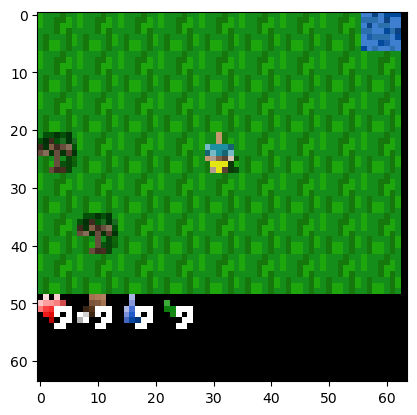

In [16]:
# Inspect the Data:
from exploration_metrics import get_unique_task_score

for ep in adults_df.itertuples():
    if len(ep.selftalk)==0:
        continue
    print('an example episode with filename: ', ep.run)
    print('participant name: ', ep.participant)
    print('example transition:', dataset_df.attrs['decode_transition'](list(ep.transition_table.items())[0][0]), 'with count:', list(ep.transition_table.items())[0][1])
    print('episode score: ', ep.reward.sum())
    print('first line of self talk from this participant:')
    print(ep.selftalk[0])
    print('wordcount:', ep.wordcount, ' wordrate: ', ep.WordRate)
    print(ep.WordRate)
    print('first frame from episode:')
    img = Image.fromarray(ep.image[0])
    plt.imshow(img)
    print(get_unique_task_score(ep.achievement_table))
    print(np.sum([min(i,1) for i in ep.action if i > 0]))
    print(len(ep.action))
    break

In [ ]:
for participant in adults_df.participant.unique():
    # Get all episodes for this participant
    participant_episodes = dataset_df[dataset_df.participant == participant]
    # Sum the lengths of each episode
    total_timesteps = participant_episodes['action'].apply(lambda actions: np.sum([min(i,1) for i in actions if i > 0])).sum()
    print(f"Participant: {participant}, total actions: {total_timesteps}")

Participant: adults_part1, total actions: 2323
Participant: adults_part10, total actions: 4112
Participant: adults_part11, total actions: 2984
Participant: adults_part12, total actions: 2684
Participant: adults_part13, total actions: 3494
Participant: adults_part14, total actions: 2580
Participant: adults_part15, total actions: 3558
Participant: adults_part16, total actions: 2627
Participant: adults_part17, total actions: 3464
Participant: adults_part18, total actions: 2670
Participant: adults_part19, total actions: 3480
Participant: adults_part2, total actions: 2782
Participant: adults_part20, total actions: 1613
Participant: adults_part22, total actions: 2724
Participant: adults_part23, total actions: 2158
Participant: adults_part24, total actions: 2323
Participant: adults_part3, total actions: 1988
Participant: adults_part4, total actions: 2362
Participant: adults_part5, total actions: 2661
Participant: adults_part6, total actions: 2376
Participant: adults_part7, total actions: 2196